In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, BatchNormalization

In [3]:
df = pd.read_csv(r'D:\Nikss\Self Pracitce\Deep learning\31 Day 31 - concertriccir2.csv')

In [4]:
df

,7.003345706103683010e-01,-2.470675778972781789e-01,0.000000000000000000e+00
0,-3.950019,2.740080,1.0
1,0.150222,-2.157638,1.0
2,-1.672050,-0.941519,1.0
3,2.560483,-1.846577,1.0
4,-1.724979,3.463930,1.0
...,...,...,...
494,2.177895,2.984489,1.0
495,1.778905,2.869205,1.0
496,0.894180,3.069959,0.0
497,0.849439,3.875435,0.0


In [5]:
df.columns = ['x', 'y', 'class']

In [6]:
df.head()

,x,y,class
0,-3.950019,2.740080,1.0
1,0.150222,-2.157638,1.0
2,-1.672050,-0.941519,1.0
3,2.560483,-1.846577,1.0
4,-1.724979,3.463930,1.0


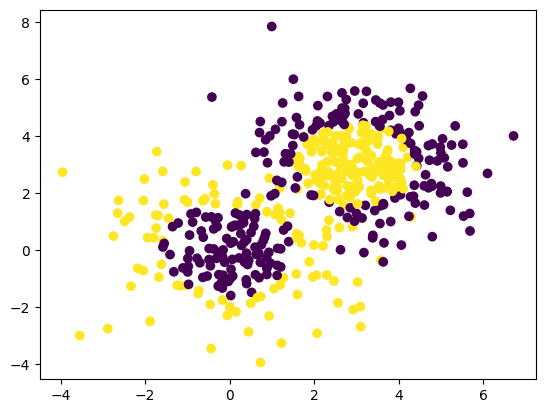

In [7]:
plt.scatter(df['x'], df['y'], c = df['class'])

In [8]:
# This is a classification dataset. We can see it's quite difficult to classify this dataset.

In [11]:
x = df.iloc[:, 0:2]
y = df.drop(x, axis = 'columns')

In [12]:
x.head()

,x,y
0,-3.950019,2.740080
1,0.150222,-2.157638
2,-1.672050,-0.941519
3,2.560483,-1.846577
4,-1.724979,3.463930


In [13]:
y.head()

,class
0,1.0
1,1.0
2,1.0
3,1.0
4,1.0


# Without BatchNormalization

In [17]:
model_1 = Sequential()

model_1.add(Dense(2, activation = 'relu', input_dim = 2))
model_1.add(Dense(2, activation = 'relu'))
model_1.add(Dense(1, activation = 'sigmoid'))

model_1.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_6 (Dense)             (None, 2)                 6         
                                                                 
 dense_7 (Dense)             (None, 2)                 6         
                                                                 
 dense_8 (Dense)             (None, 1)                 3         
                                                                 
Total params: 15 (60.00 Byte)
Trainable params: 15 (60.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [18]:
model_1.compile(loss = 'binary_crossentropy', optimizer = 'Adam', metrics = ['accuracy'])

In [20]:
history_1 = model_1.fit(x, y, epochs = 200, validation_split = 0.2)

Epoch 1/200
13/13 [==============================] - 2s 24ms/step - loss: 1.0881 - accuracy: 0.4862 - val_loss: 1.1033 - val_accuracy: 0.5700
Epoch 2/200
13/13 [==============================] - 0s 5ms/step - loss: 1.0376 - accuracy: 0.4536 - val_loss: 1.0411 - val_accuracy: 0.5700
Epoch 3/200
13/13 [==============================] - 0s 5ms/step - loss: 0.9932 - accuracy: 0.4236 - val_loss: 0.9843 - val_accuracy: 0.5700
Epoch 4/200
13/13 [==============================] - 0s 6ms/step - loss: 0.9513 - accuracy: 0.4185 - val_loss: 0.9374 - val_accuracy: 0.5700
Epoch 5/200
13/13 [==============================] - 0s 6ms/step - loss: 0.9170 - accuracy: 0.4185 - val_loss: 0.8952 - val_accuracy: 0.5700
Epoch 6/200
13/13 [==============================] - 0s 5ms/step - loss: 0.8854 - accuracy: 0.4211 - val_loss: 0.8602 - val_accuracy: 0.5700
Epoch 7/200
13/13 [==============================] - 0s 6ms/step - loss: 0.8585 - accuracy: 0.4160 - val_loss: 0.8306 - val_accuracy: 0.5700
Epoch 8/200


# With BatchNormalization

In [22]:
model_2 = Sequential()

model_2.add(Dense(3, activation = 'relu', input_dim = 2))
model_2.add(BatchNormalization())

model_2.add(Dense(2, activation = 'relu'))
model_2.add(BatchNormalization())

model_2.add(Dense(1, activation = 'sigmoid'))

model_2.summary()

# We have 12 parameters in 1st layer of BN, where 6 are trainable and 6 are non-trainable
# In 2nd layer of BN, we have 8 parameters, where 4 are trainable and 4 are non-trainable

# So in total, we have 10 non-trainable parameters.

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_12 (Dense)            (None, 3)                 9         
                                                                 
 batch_normalization_2 (Bat  (None, 3)                 12        
 chNormalization)                                                
                                                                 
 dense_13 (Dense)            (None, 2)                 8         
                                                                 
 batch_normalization_3 (Bat  (None, 2)                 8         
 chNormalization)                                                
                                                                 
 dense_14 (Dense)            (None, 1)                 3         
                                                                 
Total params: 40 (160.00 Byte)
Trainable params: 30 (1

In [23]:
model_2.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [24]:
history_2 = model_2.fit(x, y, epochs = 200, validation_split = 0.2)

Epoch 1/200
13/13 [==============================] - 2s 24ms/step - loss: 0.9091 - accuracy: 0.3960 - val_loss: 0.7764 - val_accuracy: 0.5200
Epoch 2/200
13/13 [==============================] - 0s 6ms/step - loss: 0.8648 - accuracy: 0.4637 - val_loss: 0.7423 - val_accuracy: 0.4500
Epoch 3/200
13/13 [==============================] - 0s 8ms/step - loss: 0.8755 - accuracy: 0.4211 - val_loss: 0.7093 - val_accuracy: 0.4700
Epoch 4/200
13/13 [==============================] - 0s 5ms/step - loss: 0.8607 - accuracy: 0.4085 - val_loss: 0.6826 - val_accuracy: 0.5000
Epoch 5/200
13/13 [==============================] - 0s 6ms/step - loss: 0.8395 - accuracy: 0.4461 - val_loss: 0.6645 - val_accuracy: 0.5100
Epoch 6/200
13/13 [==============================] - 0s 5ms/step - loss: 0.8322 - accuracy: 0.4411 - val_loss: 0.6481 - val_accuracy: 0.5300
Epoch 7/200
13/13 [==============================] - 0s 5ms/step - loss: 0.8293 - accuracy: 0.4411 - val_loss: 0.6372 - val_accuracy: 0.5500
Epoch 8/200


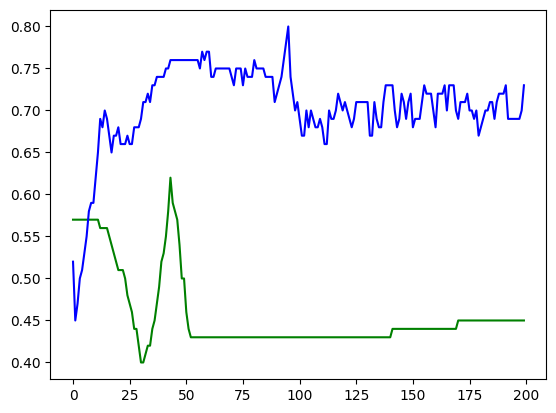

In [27]:
plt.plot(history_1.history['val_accuracy'], color = 'green')    # Without BN
plt.plot(history_2.history['val_accuracy'], color = 'blue')   # With BN

# `Next topic:` Day 32 - Optimizers in Deep Learning.